 # Task-11 (Week-4)

**Dataset** :- 'Admission_Prediction.csv'

**Objective** :- Implement and evaluate an XGBoost model for predictive analysis, focusing on regularization techniques and early stopping to prevent overfitting on complex applicant data

In [10]:
# Import Library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

In [11]:
# Load the dataset

df = pd.read_csv("Admission_Prediction.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (1000, 17)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Year,Application_Date,University_Name,region,Admission Status,Duration_Months,Dropout_Event,Dropout-free survival
0,104,317,104,2,4.5,4.0,8.47,0,0.57,2022,03-01-2022,Indian Institute of Technology Bombay,West,Rejected,36,0,0.536473
1,170,311,99,2,2.5,3.0,7.98,0,0.65,2022,09-01-2022,Indian Institute of Technology Delhi,North,Rejected,18,1,0.973000
2,138,316,100,2,1.5,3.0,8.16,1,0.71,2022,12-01-2022,Indian Institute of Technology Delhi,North,Rejected,33,0,0.597989
3,147,315,105,3,2.0,2.5,8.48,0,0.75,2022,13-01-2022,Indian Institute of Technology Delhi,North,Accepted,33,0,0.597989
4,117,299,102,3,4.0,3.5,8.62,0,0.56,2022,14-01-2022,Indian Institute of Technology Delhi,North,Rejected,28,1,0.734170


In [12]:
# Data preprocessing

print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Records:", df.duplicated().sum())

Missing Values:
Serial No.               0
GRE Score                0
TOEFL Score              0
University Rating        0
SOP                      0
LOR                      0
CGPA                     0
Research                 0
Chance of Admit          0
Year                     0
Application_Date         0
University_Name          0
region                   0
Admission Status         0
Duration_Months          0
Dropout_Event            0
Dropout-free survival    0
dtype: int64
Duplicate Records: 0


In [16]:
# Identify the target column

print(df.columns.tolist())

# Set the correct target column:
target_column = "Admission Status"  # Replace with your actual target column

X = df.drop(columns=[target_column])
y = df[target_column]

['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Year', 'Application_Date', 'University_Name', 'region', 'Admission Status', 'Duration_Months', 'Dropout_Event', 'Dropout-free survival']


In [17]:
# Encode the target and split the data

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)

print("Target Classes:", le.classes_)

Target Classes: ['Accepted' 'Rejected']


In [19]:
# Split the dataset into training and testing sets

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [20]:
# Encode applicant features

X_train = pd.get_dummies(X_train, drop_first=True)
X_val = pd.get_dummies(X_val, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [21]:
# Handle missing numerical values using training-set

medians = X_train.median()

X_train = X_train.fillna(medians)
X_val = X_val.fillna(medians)
X_test = X_test.fillna(medians)

In [22]:
# Implement XGBoost with regularization

xgb_model = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,

    reg_alpha=0.1,
    reg_lambda=5,
    gamma=0.1,

    objective="binary:logistic",
    eval_metric="logloss",
    early_stopping_rounds=30,

    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("XGBoost Model Training Completed!")

XGBoost Model Training Completed!


In [23]:
# Evaluate the XGBoost model

# Predictions
y_train_pred = xgb_model.predict(X_train)
y_test_pred = xgb_model.predict(X_test)

# Evaluation metrics
print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))

print("\nPrecision:", precision_score(y_test, y_test_pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, y_test_pred, average="weighted", zero_division=0))
print("F1 Score:", f1_score(y_test, y_test_pred, average="weighted", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

Training Accuracy: 1.0
Testing Accuracy: 1.0

Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        87
           1       1.00      1.00      1.00       113

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



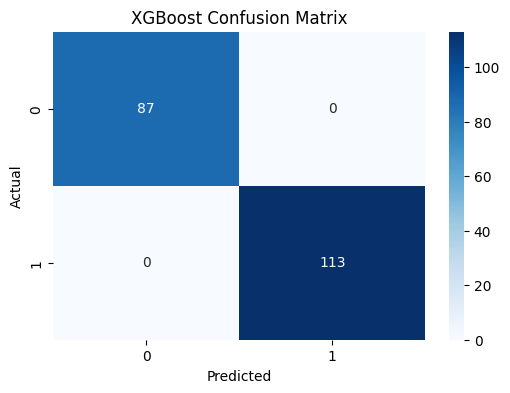

In [24]:
# Confusion matrix

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

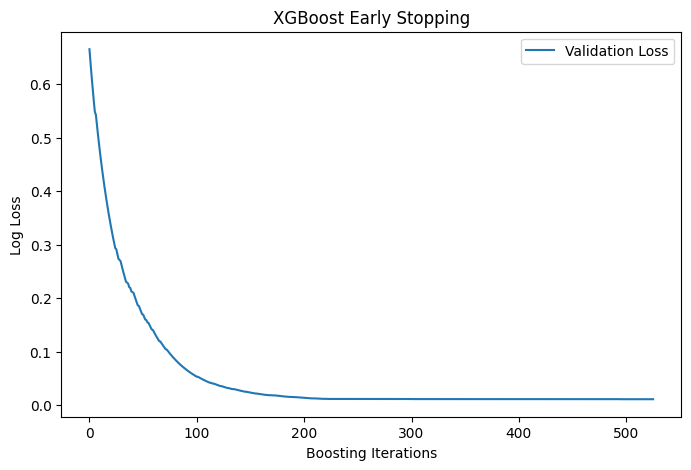

Best Iteration: 495


In [25]:
# Check overfitting using a graph

results = xgb_model.evals_result()

plt.figure(figsize=(8, 5))

plt.plot(
    results["validation_0"]["logloss"],
    label="Validation Loss"
)

plt.title("XGBoost Early Stopping")
plt.xlabel("Boosting Iterations")
plt.ylabel("Log Loss")
plt.legend()
plt.show()

print("Best Iteration:", xgb_model.best_iteration)

<Figure size 1000x600 with 0 Axes>

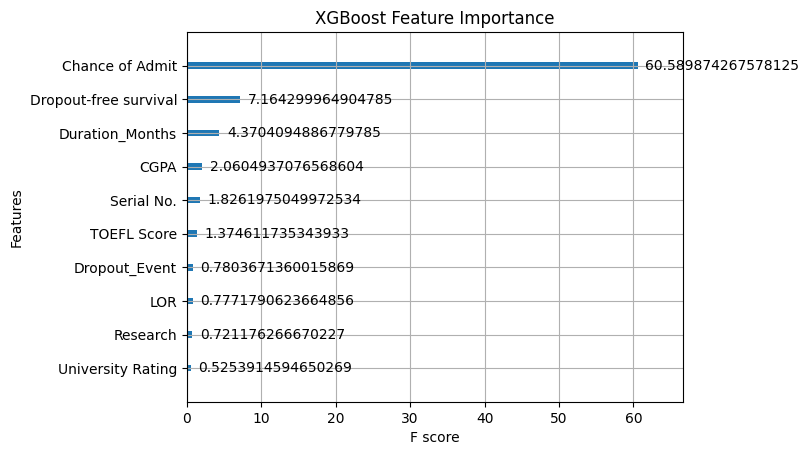

In [26]:
# Feature importance

from xgboost import plot_importance

plt.figure(figsize=(10, 6))

plot_importance(
    xgb_model,
    max_num_features=10,
    importance_type="gain"
)

plt.title("XGBoost Feature Importance")
plt.show()